<a href="https://colab.research.google.com/github/NandiniN2215/BIS_LAB/blob/main/Grey_wolf_optimizer_delivery_route_distance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


========== OPTIMIZED DELIVERY ROUTE ==========
Best Route: Depot -> F -> A -> H -> B -> G -> C -> D -> E -> Depot
Minimum Distance: 28.5644

========== PERFORMANCE COMPARISON ==========
Average Random Route Distance: 52.8396
GWO Optimized Distance: 28.5644
Improvement (%): 45.94


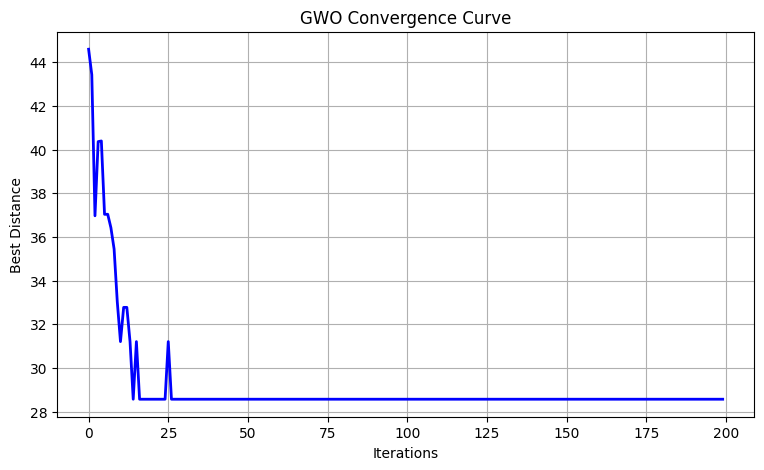

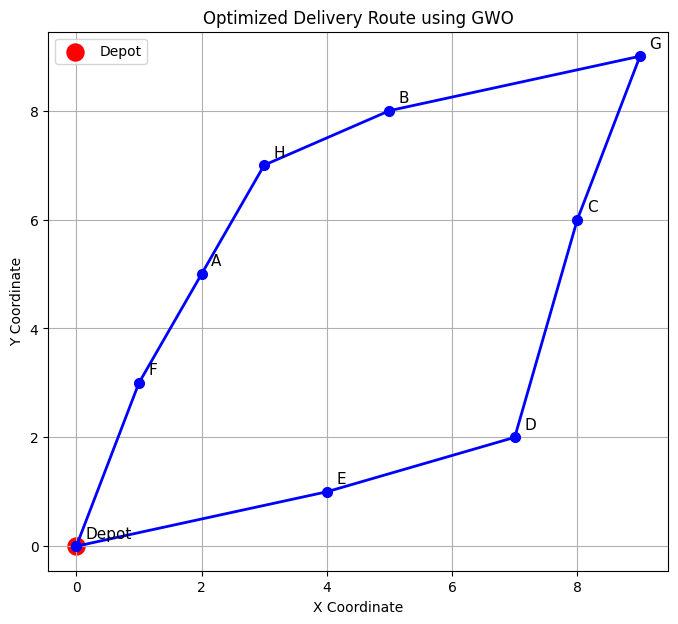

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import random

# ==========================================
# 1. PROBLEM DEFINITION
# ==========================================

locations = {
    'Depot': (0, 0),
    'A': (2, 5),
    'B': (5, 8),
    'C': (8, 6),
    'D': (7, 2),
    'E': (4, 1),
    'F': (1, 3),
    'G': (9, 9),
    'H': (3, 7)
}

cities = list(locations.keys())[1:]
n_cities = len(cities)

# Distance matrix
distance_matrix = np.zeros((n_cities + 1, n_cities + 1))

all_locations = list(locations.keys())

for i, city1 in enumerate(all_locations):
    for j, city2 in enumerate(all_locations):
        x1, y1 = locations[city1]
        x2, y2 = locations[city2]

        distance_matrix[i][j] = np.sqrt(
            (x1 - x2)**2 + (y1 - y2)**2
        )


# ==========================================
# 2. FITNESS FUNCTION
# ==========================================

def decode_wolf(wolf):
    """
    Convert continuous random keys into
    a discrete delivery route.
    """
    order = np.argsort(wolf)
    return order


def fitness(wolf):
    route = decode_wolf(wolf)

    total_distance = 0

    # Depot to first delivery location
    total_distance += distance_matrix[0][route[0] + 1]

    # Between delivery locations
    for i in range(len(route) - 1):
        total_distance += distance_matrix[
            route[i] + 1
        ][
            route[i + 1] + 1
        ]

    # Last location back to depot
    total_distance += distance_matrix[
        route[-1] + 1
    ][0]

    return total_distance


# ==========================================
# 3. GREY WOLF OPTIMIZER PARAMETERS
# ==========================================

num_wolves = 30
max_iterations = 200
dimension = n_cities

lower_bound = 0
upper_bound = 1

# Initialize wolves
wolves = np.random.uniform(
    lower_bound,
    upper_bound,
    (num_wolves, dimension)
)

convergence_curve = []


# ==========================================
# 4. GREY WOLF OPTIMIZATION
# ==========================================

for iteration in range(max_iterations):

    # Evaluate fitness
    fitness_values = np.array([
        fitness(wolf) for wolf in wolves
    ])

    # Sort wolves based on fitness
    sorted_indices = np.argsort(fitness_values)

    alpha = wolves[sorted_indices[0]].copy()
    beta = wolves[sorted_indices[1]].copy()
    delta = wolves[sorted_indices[2]].copy()

    alpha_score = fitness_values[sorted_indices[0]]

    convergence_curve.append(alpha_score)

    # Linearly decrease exploration parameter
    a = 2 - iteration * (2 / max_iterations)

    new_wolves = np.zeros_like(wolves)

    # Update each wolf
    for i in range(num_wolves):

        X = wolves[i]

        # Alpha influence
        r1 = np.random.rand(dimension)
        r2 = np.random.rand(dimension)

        A1 = 2 * a * r1 - a
        C1 = 2 * r2

        D_alpha = abs(C1 * alpha - X)
        X1 = alpha - A1 * D_alpha

        # Beta influence
        r1 = np.random.rand(dimension)
        r2 = np.random.rand(dimension)

        A2 = 2 * a * r1 - a
        C2 = 2 * r2

        D_beta = abs(C2 * beta - X)
        X2 = beta - A2 * D_beta

        # Delta influence
        r1 = np.random.rand(dimension)
        r2 = np.random.rand(dimension)

        A3 = 2 * a * r1 - a
        C3 = 2 * np.random.rand(dimension)

        D_delta = abs(C3 * delta - X)
        X3 = delta - A3 * D_delta

        # Final position update
        new_position = (X1 + X2 + X3) / 3

        # Boundary handling
        new_position = np.clip(
            new_position,
            lower_bound,
            upper_bound
        )

        new_wolves[i] = new_position

    wolves = new_wolves


# ==========================================
# 5. FIND BEST SOLUTION
# ==========================================

final_fitness = np.array([
    fitness(wolf) for wolf in wolves
])

best_index = np.argmin(final_fitness)

best_wolf = wolves[best_index]
best_route = decode_wolf(best_wolf)
best_distance = fitness(best_wolf)

print("\n========== OPTIMIZED DELIVERY ROUTE ==========")

route_names = ['Depot']

for city_index in best_route:
    route_names.append(cities[city_index])

route_names.append('Depot')

print("Best Route:", " -> ".join(route_names))
print("Minimum Distance:", round(best_distance, 4))


# ==========================================
# 6. RANDOM ROUTE COMPARISON
# ==========================================

random_distances = []

for _ in range(100):
    random_route = np.random.permutation(n_cities)

    random_wolf = np.empty(n_cities)

    # Construct random keys that decode to random_route
    for rank, city_index in enumerate(random_route):
        random_wolf[city_index] = rank / n_cities

    random_distances.append(fitness(random_wolf))

average_random_distance = np.mean(random_distances)

print("\n========== PERFORMANCE COMPARISON ==========")
print("Average Random Route Distance:",
      round(average_random_distance, 4))

print("GWO Optimized Distance:",
      round(best_distance, 4))

improvement = (
    (average_random_distance - best_distance)
    / average_random_distance
) * 100

print("Improvement (%):", round(improvement, 2))


# ==========================================
# 7. CONVERGENCE GRAPH
# ==========================================

plt.figure(figsize=(9, 5))

plt.plot(
    convergence_curve,
    color='blue',
    linewidth=2
)

plt.title("GWO Convergence Curve")
plt.xlabel("Iterations")
plt.ylabel("Best Distance")
plt.grid(True)

plt.show()


# ==========================================
# 8. ROUTE VISUALIZATION
# ==========================================

route_x = [locations['Depot'][0]]
route_y = [locations['Depot'][1]]

for city_index in best_route:
    city = cities[city_index]

    route_x.append(locations[city][0])
    route_y.append(locations[city][1])

route_x.append(locations['Depot'][0])
route_y.append(locations['Depot'][1])

plt.figure(figsize=(8, 7))

plt.plot(
    route_x,
    route_y,
    'b-o',
    linewidth=2,
    markersize=7
)

for city, (x, y) in locations.items():
    plt.text(x + 0.15, y + 0.15, city, fontsize=11)

plt.scatter(0, 0, color='red', s=150, label='Depot')

plt.title("Optimized Delivery Route using GWO")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")

plt.legend()
plt.grid(True)
plt.show()
